*Previous notebook: the hyperparameter tuning process (grid search and Optuna). — This notebook: batch normalization, implemented and compared with the baseline and improved networks.*

### Setup

This notebook builds on **4.1**. The cell below re-runs `4.1_baseline_vs_improved.ipynb` silently to recreate the dataset, the network helpers, `train_improved`, `regression_report` and the trained baseline / improved models. It retrains both models, so it takes a few minutes.

In [1]:
%%capture
%run "4.1_baseline_vs_improved.ipynb"

# Normalizing Activations in a Network

In the rise of deep learning, one of the most important ideas has been an algorithm called batch normalization, created by two researchers, Sergey Ioffe and Christian Szegedy.

Batch Normalization speeds up learning.

Before we normalized input by subtracting the mean and dividing by variance. This helped a lot for the shape of the cost function and for reaching the minimum point faster.

The question is: for any hidden layer can we normalize A[l] to train W[l+1], b[l+1] faster? This is what batch normalization is about.

There are some debates in the deep learning literature about whether you should normalize values before the activation function Z[l] or after applying the activation function A[l]. In practice, normalizing Z[l] is done much more often and that is what Andrew Ng presents.

---

# Algorithm

Given:
Z[l] = [z(1), ..., z(m)], i = 1 to m (for each input)

    mean = 1/m * sum(z[i])

    variance = 1/m * sum((z[i] - mean)**2)

    Z_norm[i] = (z[i] - mean) / np.sqrt(variance + epsilon)
    # add epsilon for numerical stability if variance = 0

Forcing the inputs to a distribution with zero mean and variance of 1.

    Z_tilde[i] = gamma * Z_norm[i] + beta

To make inputs belong to other distribution (with other mean and variance).

gamma and beta are learnable parameters of the model.

Making the NN learn the distribution of the outputs.

Note:
if gamma = sqrt(variance + epsilon) and beta = mean then:

    Z_tilde[i] = z[i]

---

# Why Does Batch Normalization Work?

The first reason is the same reason as why we normalize X.

The second reason is that batch normalization reduces the problem of input values changing (shifting).

Batch normalization does some regularization:

Each mini batch is scaled by the mean/variance computed of that mini-batch.

This adds some noise to the values Z[l] within that mini batch. So similar to dropout it adds some noise to each hidden layer's activations.

This has a slight regularization effect.

Using bigger size of the mini-batch you are reducing noise and therefore regularization effect.

Don't rely on batch normalization as a regularization. It's intended for normalization of hidden units, activations and therefore speeding up learning. For regularization use other regularization techniques (L2 or dropout).

---

# Batch Normalization at Test Time

When we train a NN with Batch normalization, we compute the mean and the variance of the mini-batch.

In testing we might need to process examples one at a time. The mean and the variance of one example won't make sense.

We have to compute an estimated value of mean and variance to use it in testing time.

We can use the weighted average across the mini-batches.

We will use the estimated values of the mean and variance to test.

This method is also sometimes called "Running average".

In practice most often you will use a deep learning framework and it will contain some default implementation of doing such a thing.

In [2]:
EPS = 1e-8

# ── BN primitives ─────────────────────────────────────────────────────────────
def bn_forward(Z, gamma, beta, running_mean, running_var,
               training=True, momentum=0.9):
    if training:
        mean    = Z.mean(axis=0, keepdims=True)
        var     = Z.var(axis=0,  keepdims=True)
        Z_norm  = (Z - mean) / np.sqrt(var + EPS)
        Z_tilde = gamma * Z_norm + beta
        running_mean[:] = momentum * running_mean + (1 - momentum) * mean
        running_var[:]  = momentum * running_var  + (1 - momentum) * var
        cache = (Z, Z_norm, mean, var, gamma)
    else:
        Z_norm  = (Z - running_mean) / np.sqrt(running_var + EPS)
        Z_tilde = gamma * Z_norm + beta
        cache   = None
    return Z_tilde, cache


def bn_backward(dZ_tilde, cache):
    """Closed-form BN gradient (Ioffe & Szegedy)."""
    Z, Z_norm, mean, var, gamma = cache
    m       = Z.shape[0]
    dgamma  = (dZ_tilde * Z_norm).sum(axis=0, keepdims=True)
    dbeta   = dZ_tilde.sum(axis=0, keepdims=True)
    dZ_norm = dZ_tilde * gamma
    std_inv = 1.0 / np.sqrt(var + EPS)
    dZ = (std_inv / m) * (
        m * dZ_norm
        - dZ_norm.sum(axis=0, keepdims=True)
        - Z_norm * (dZ_norm * Z_norm).sum(axis=0, keepdims=True)
    )
    return dZ, dgamma, dbeta

In [3]:
# ── BN-aware network ──────────────────────────────────────────────────────────
def init_bn_params(layer_sizes):
    bn = {}
    for i in range(1, len(layer_sizes) - 1):   # hidden layers only
        n = layer_sizes[i]
        bn[f'gamma{i}'] = np.ones((1, n))
        bn[f'beta{i}']  = np.zeros((1, n))
        bn[f'rm{i}']    = np.zeros((1, n))      # running mean
        bn[f'rv{i}']    = np.zeros((1, n))      # running variance
    return bn


def forward_bn(X, params, bn, training=True):
    cache = {'a0': X}
    a, n_layers = X, len(params) // 2
    for i in range(1, n_layers):                # hidden — BN then ReLU
        z = a @ params[f'W{i}'] + params[f'b{i}']
        zt, bn_cache = bn_forward(z, bn[f'gamma{i}'], bn[f'beta{i}'],
                                  bn[f'rm{i}'], bn[f'rv{i}'], training=training)
        a = relu(zt)
        cache.update({f'z{i}': z, f'zt{i}': zt, f'bn{i}': bn_cache, f'a{i}': a})
    i = n_layers                                # output — linear, no BN
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = cache[f'a{i}'] = z
    return z, cache


def backward_bn(y, y_hat, params, cache, bn):
    m, n_layers = y.shape[0], len(params) // 2
    grads, bn_grads = {}, {}
    delta = -(y - y_hat) / m
    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)
        if i > 1:
            # backprop through ReLU on z_tilde, then through BN to reach z
            delta = delta @ params[f'W{i}'].T * relu_deriv(cache[f'zt{i-1}'])
            delta, dgamma, dbeta = bn_backward(delta, cache[f'bn{i-1}'])
            bn_grads[f'dgamma{i-1}'] = dgamma
            bn_grads[f'dbeta{i-1}']  = dbeta
    return grads, bn_grads

In [4]:
def update_bn_params(bn, bn_grads, lr):
    for key, grad in bn_grads.items():
        bn[key[1:]] -= lr * grad        # 'dgamma1' → 'gamma1'
    return bn


def train_bn(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    bn     = init_bn_params(layer_sizes)
    tl, vl = [], []
    start  = time.time()
    for _ in range(epochs):
        y_hat, cache = forward_bn(X_tr, params, bn, training=True)
        grads, bg    = backward_bn(y_tr, y_hat, params, cache, bn)
        params       = update_params(params, grads, lr)
        bn           = update_bn_params(bn, bg, lr)
        tl.append(mse(y_tr, y_hat))
        y_hat_v, _   = forward_bn(X_v, params, bn, training=False)
        vl.append(mse(y_v, y_hat_v))
    elapsed = time.time() - start
    print(f'Final train MSE: {tl[-1]:.4f}  |  val MSE: {vl[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, bn, tl, vl

In [5]:
# ── Train ─────────────────────────────────────────────────────────────────────
layer_sizes = [1, 64, 128, 64, 1]
print('Training with Batch Normalisation…')
params_bn, bn, tl_bn, vl_bn = train_bn(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=layer_sizes, lr=1e-2, epochs=2000, seed=0
)

y_hat_bn_test, _ = forward_bn(X_test_n, params_bn, bn, training=False)
test_mse_bn = mse(y_test, y_hat_bn_test)
print()
regression_report('BN', y_test, y_hat_bn_test)

Training with Batch Normalisation…


Final train MSE: 0.0363  |  val MSE: 0.0354  |  time: 34.96s

BN         | MSE=0.0425  RMSE=0.2062  MAE=0.1637  R²=0.9242


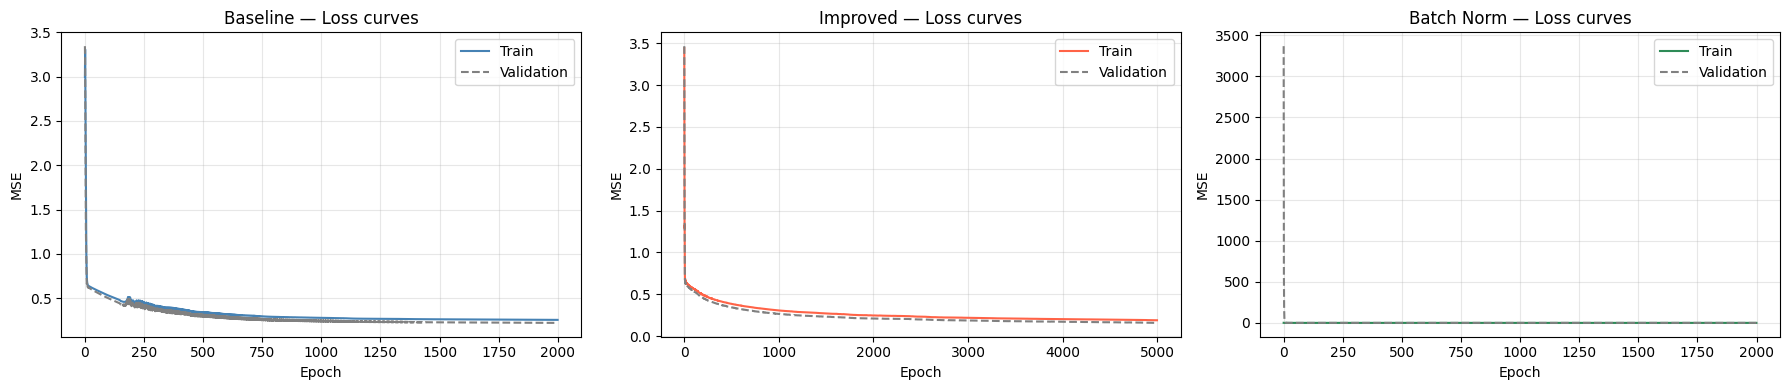

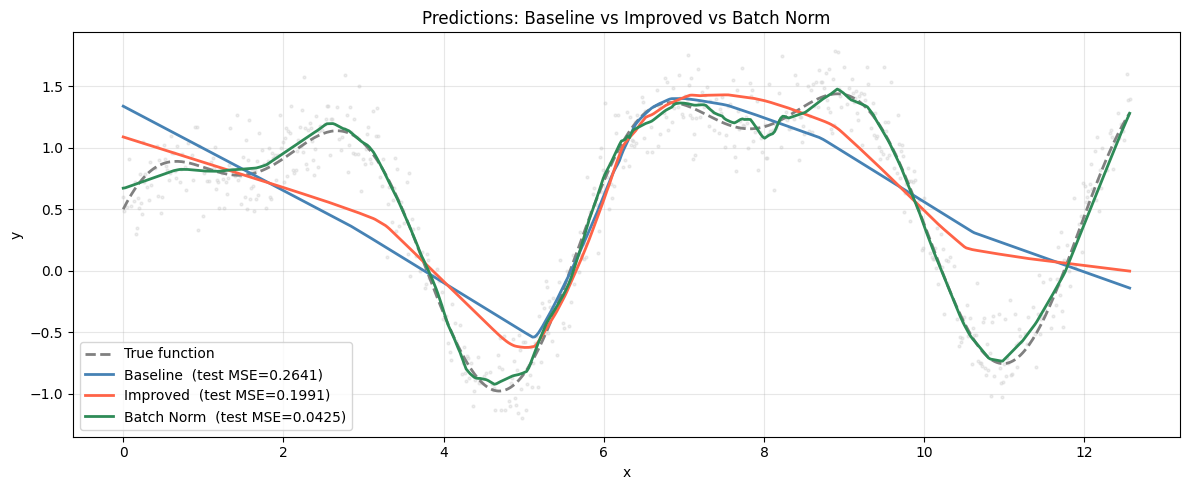

In [6]:
# ── Loss curves comparison ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, tl, vl, title, color in zip(
        axes,
        [tl_base, tl_imp,  tl_bn],
        [vl_base, vl_imp,  vl_bn],
        ['Baseline', 'Improved', 'Batch Norm'],
        ['steelblue', 'tomato', 'seagreen']):
    ax.plot(tl, color=color, label='Train')
    ax.plot(vl, color='gray', linestyle='--', label='Validation')
    ax.set_title(f'{title} — Loss curves')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE')
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# ── Prediction curves ─────────────────────────────────────────────────────────
X_plot_n    = np.linspace(X_train_n.min(), X_train_n.max(), 500).reshape(-1, 1)
X_plot      = X_plot_n * sigma + mu
y_true_plot = np.sin(X_plot) + 0.5 * np.cos(2 * X_plot) + 0.3 * np.log(X_plot + 1)

plt.figure(figsize=(12, 5))
plt.plot(X_plot, y_true_plot, '--', color='gray', lw=2, label='True function')
plt.scatter(X_train, y_train, color='lightgray', s=4, alpha=0.4)
plt.plot(X_plot, forward(X_plot_n, params_base)[0],
         color='steelblue', lw=2, label=f'Baseline  (test MSE={test_mse_base:.4f})')
plt.plot(X_plot, forward_dropout(X_plot_n, params_imp, training=False)[0],
         color='tomato',    lw=2, label=f'Improved  (test MSE={test_mse_imp:.4f})')
plt.plot(X_plot, forward_bn(X_plot_n, params_bn, bn, training=False)[0],
         color='seagreen',  lw=2, label=f'Batch Norm  (test MSE={test_mse_bn:.4f})')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Predictions: Baseline vs Improved vs Batch Norm')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### Why BN outperforms everything else on this problem

Probably is because it use the entire training set as a single batch (full-batch BN). With normal mini-batches (e.g. batch size 32), BN introduces noise because the statistics of each mini-batch fluctuate. Here, however, BN calculates the exact mean and variance of the 700 training samples at every step → perfect normalisation, no noise, and gradients that are always well-conditioned.
The main challenge is to propagate gradients through four layers and BN solves exactly this